# Análise de Dados Públicos de Usuários e Repositórios Moçambicanos no GitHub  

1. **Usuários e Repositórios Mais Curtidos:**  
   Identificação dos perfis e projectos que recebem maior reconhecimento e engajamento da comunidade.  

2. **Adesão Anual de Usuários Moçambicanos no GitHub:**  
   Análise do crescimento do número de desenvolvedores moçambicanos que se juntam à plataforma ao longo dos anos.  

3. **Variação Anual de Criação de Repositórios Públicos:**  
   Avaliação de como a criação de novos repositórios evolui anualmente, reflectindo a inovação da comunidade.  

4. **Linguagens Mais Usadas em Repositórios Públicos:**  
   Mapeamento das linguagens de programação predominantes nos repositórios moçambicanos.  

5. **Distribuição de Repositórios Curtidos (Nacionais vs. Internacionais):**  
   Comparação entre os repositórios que recebem mais curtidas, distinguindo os projectos nacionais dos internacionais.  

6. **Linguagens Mais Curtidas:**  
   Análise das linguagens de programação que mais recebem reconhecimento e curtidas em repositórios.

# Main

In [1]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

from dotenv import load_dotenv
load_dotenv()

import warnings
warnings.filterwarnings("ignore")

In [2]:
dir_name = os.getenv('DIR_NAME')
base_path = f'../data/{dir_name}'
os.makedirs(base_path, exist_ok=True)

users_data = pd.read_csv(f'{base_path}/users_data.csv')
repos_data = pd.read_csv(f'{base_path}/repos_data.csv')
starred_data = pd.read_csv(f'{base_path}/starred_repos_data.csv')
starred_repos_users_ids = pd.read_csv(f'{base_path}/starred_repos_users_ids.csv')
issues_data = pd.read_csv(f'{base_path}/issues_data.csv')

In [3]:
print(users_data.columns)
print(repos_data.columns)
print(starred_data.columns)
print(starred_repos_users_ids.columns)
print(issues_data.columns)

Index(['login', 'id', 'name', 'company', 'blog', 'location', 'email', 'bio',
       'twitter_username', 'public_repos', 'public_gists', 'followers',
       'following', 'created_at', 'updated_at'],
      dtype='object')
Index(['id', 'name', 'full_name', 'owner_id', 'html_url', 'description',
       'fork', 'created_at', 'updated_at', 'pushed_at', 'homepage', 'size',
       'stargazers_count', 'watchers_count', 'language', 'forks_count',
       'open_issues_count', 'topics', 'default_branch', 'license_key',
       'license_name'],
      dtype='object')
Index(['id', 'name', 'full_name', 'owner_id', 'html_url', 'description',
       'fork', 'created_at', 'updated_at', 'pushed_at', 'homepage', 'size',
       'stargazers_count', 'watchers_count', 'language', 'forks_count',
       'open_issues_count', 'license_key', 'license_name', 'topics',
       'default_branch'],
      dtype='object')
Index(['user_id', 'repo_id', 'owner_id'], dtype='object')
Index(['id', 'number', 'title', 'user_id', 'st

## Cabeçalhos das Tabelas

In [4]:
users_data.head() # Dados de Usuários

,login,id,name,company,blog,location,email,bio,twitter_username,public_repos,public_gists,followers,following,created_at,updated_at
0,opanguane,48277037,Oswald,Pathfinder International,pathfinder.org,Mozambique,NaN,NaN,NaN,2,1,6,8,2019-03-06T08:43:56Z,2026-03-07T07:18:35Z
1,EdsonMaleiane995,71436199,Edson Maleiane,ODISSEIA,NaN,"Mozambique, Maputo",NaN,NaN,NaN,0,0,0,0,2020-09-17T09:40:51Z,2020-09-29T12:59:24Z
2,leonelmatsinhe,13402312,Leonel Zacarias Matsinhe,"LSA, EI",https://.lsa.co.mz,Mozambique,leonelmatsinhe@gmail.com,NaN,NaN,11,0,1,5,2015-07-19T08:56:17Z,2026-10-20T19:28:17Z
3,IvanBila,13482373,Connoisseur,@bazara,https://ivanbila.github.io/,"Maputo, Mozambique",NaN,until cmd>/tmp/o 2>/tmp/e; do tail -1 /tmp/e>>...,NaN,8,1,137,77,2015-07-24T10:12:24Z,2026-09-10T14:39:23Z
4,NipepeEdu,211449552,NipepeEdu,"Serviço Distrital de Educação, Juventude e Tec...",NaN,"Nipepe,Niassa,Moçambique",NaN,NipepeEdu\r\nDescrição:\r\nNipepeEdu é um apl...,NaN,1,0,0,0,2025-05-13T04:47:19Z,2025-05-13T05:50:22Z


In [5]:
repos_data.head() # Dados de Repositórios Criados

,id,name,full_name,owner_id,html_url,description,fork,created_at,updated_at,pushed_at,homepage,size,stargazers_count,watchers_count,language,forks_count,open_issues_count,topics,default_branch,license_key,license_name
0,372937702,RepoVazio,Lopes-MSJ/RepoVazio,57982422,https://github.com/Lopes-MSJ/RepoVazio,NaN,False,2021-06-01T19:16:33Z,2021-06-01T20:25:44Z,2021-06-01T20:25:42Z,NaN,1,0,0,NaN,0,0,NaN,main,NaN,NaN
1,307709722,github-slideshow,Adjixx47/github-slideshow,73537499,https://github.com/Adjixx47/github-slideshow,A robot powered training repository :robot:,False,2020-10-27T13:30:44Z,2022-12-07T18:35:39Z,2020-10-27T13:30:51Z,https://lab.github.com/githubtraining/introduc...,3516,1,1,Ruby,0,1,NaN,master,mit,MIT License
2,1352355140,Nboard,OrnanAJ/Nboard,99444012,https://github.com/OrnanAJ/Nboard,Nothing inspired keyboard for android,True,2026-08-31T11:54:18Z,2026-08-31T11:54:18Z,2026-08-31T12:03:07Z,NaN,4993,0,0,NaN,0,0,NaN,main,agpl-3.0,GNU Affero General Public License v3.0
3,457956238,OrnanAJ09,OrnanAJ/OrnanAJ09,99444012,https://github.com/OrnanAJ/OrnanAJ09,Config files for my GitHub profile.,False,2022-02-10T21:39:57Z,2022-02-10T21:39:57Z,2022-02-10T21:39:58Z,https://github.com/OrnanAJ09,0,0,0,NaN,0,0,"config, github-config",main,NaN,NaN
4,1181355382,EduPag-MVP,Chande21/EduPag-MVP,208755920,https://github.com/Chande21/EduPag-MVP,Created with StackBlitz ⚡️,False,2026-03-14T03:13:52Z,2026-03-14T03:14:06Z,2026-03-14T03:14:03Z,https://stackblitz.com/edit/sb1-bcaskqg9,60,0,0,TypeScript,0,0,NaN,main,NaN,NaN


In [6]:
starred_data.head() # Dados de Repositórios Curtidos

,id,name,full_name,owner_id,html_url,description,fork,created_at,updated_at,pushed_at,homepage,size,stargazers_count,watchers_count,language,forks_count,open_issues_count,license_key,license_name,topics,default_branch
0,291137,ohmyzsh,ohmyzsh/ohmyzsh,22552083,https://github.com/ohmyzsh/ohmyzsh,"🙃 A delightful community-driven (with 2,500+...",False,2009-08-28T18:15:37Z,2026-11-01T09:22:46Z,2026-10-27T11:37:50Z,https://ohmyz.sh,14373,190278,190278,Shell,28050,303,mit,MIT License,"cli, cli-app, oh-my-zsh, oh-my-zsh-plugin, oh-...",master
1,1092691652,social-sentiment-pricing,pema37/social-sentiment-pricing,122934213,https://github.com/pema37/social-sentiment-pri...,AI-driven Social Sentiment Pricing assistant f...,False,2025-11-09T05:28:57Z,2026-10-12T00:30:15Z,2026-05-18T21:53:32Z,NaN,6549,1,1,Python,1,1,mit,MIT License,NaN,main
2,1197652028,skills,google/skills,1342004,https://github.com/google/skills,Agent Skills for Google products and technologies,False,2026-03-31T19:02:20Z,2026-11-01T09:17:50Z,2026-10-31T13:39:40Z,NaN,4348,21744,21744,Python,1853,24,apache-2.0,Apache License 2.0,"google, googlecloud, skills",main
3,1104332987,MiroFish,666ghj/MiroFish,110395318,https://github.com/666ghj/MiroFish,A Simple and Universal Swarm Intelligence Engi...,False,2025-11-26T04:23:02Z,2026-11-01T09:37:25Z,2026-10-16T03:32:19Z,https://mirofish.ai,16817,83152,83152,Python,12575,216,agpl-3.0,GNU Affero General Public License v3.0,"agent-memory, financial-forecasting, future-pr...",main
4,737720200,Point-Of-Sale-System,chamikasrimantha/Point-Of-Sale-System,137622812,https://github.com/chamikasrimantha/Point-Of-S...,This repository contains the source code for a...,False,2024-01-01T08:16:40Z,2026-03-16T12:26:02Z,2024-01-07T12:52:05Z,NaN,491,4,4,JavaScript,3,0,mit,MIT License,"layered-architecture, reactjs, rest-api, sprin...",main


In [7]:
starred_repos_users_ids.head() # Quem curtiu repo de quem

,user_id,repo_id,owner_id
0,5244834,291137,22552083
1,39951469,1092691652,122934213
2,182628846,1197652028,1342004
3,182628846,1104332987,110395318
4,77127716,737720200,137622812


In [8]:
issues_data.head() # Dados de Issues

,id,number,title,user_id,state,comments,created_at,updated_at,closed_at,body,reactions_total_count,repo_id
0,3254691311,36,⚠️ Installation fails on Termux due to missing...,95558305,open,0,2025-07-23T03:19:39Z,2025-07-23T03:19:51Z,NaN,### Problem\n\nInstalling `lazy-ninja` fails o...,0,929968939
1,370788063,2,Add Travis CI,19359776,open,0,2018-10-16T20:34:16Z,2018-10-16T20:34:16Z,NaN,NaN,0,120504462
2,370787993,1,Update to CL 2.0,19359776,open,1,2018-10-16T20:34:07Z,2018-10-17T14:47:53Z,NaN,NaN,0,120504462
3,366415999,4,AppleAndOrange.java,33977992,open,0,2018-10-03T16:09:58Z,2018-10-03T16:09:58Z,NaN,Some variable names are not meaningful.,0,114606168
4,334939212,3,Incomplete Repository,16766726,open,0,2018-06-22T16:18:57Z,2018-06-22T16:18:57Z,NaN,A few things missing on this repository:\r\n\r...,0,114606168


## Usuários e Repositórios Mais Curtidos

In [9]:
# Filtrar repositórios nacionais 
nacional_repos_data = repos_data[repos_data['owner_id'].isin(users_data['id'].unique())]

df_merged = nacional_repos_data.merge(
    users_data[['id', 'login']],  
    left_on='owner_id', 
    right_on='id', 
    how='left'
)

df_user_stars = (
    df_merged
    .groupby('login', as_index=False)
    .agg(total_stars=('stargazers_count', 'sum'))
)

df_top_users = df_user_stars.sort_values(
    'total_stars', ascending=False
).head(10)

df_top_repos = nacional_repos_data.sort_values(
    'stargazers_count', ascending=False
).head(10)

final_table = pd.DataFrame({
    'Usuário': df_top_users['login'].values,
    'Estrelas (user)': df_top_users['total_stars'].values,
    'Repositório': df_top_repos['name'].values,
    'Estrelas (repo)': df_top_repos['stargazers_count'].values
})

# Nota: A disposição das linhas não indica relação entre o repositório e o usuário
final_table


,Usuário,Estrelas (user),Repositório,Estrelas (repo)
0,arnaldo-tomo,544,sqlifinder,398
1,americo,427,rtf-html-php,106
2,henck,244,arkos,91
3,isneezy,226,open-weather-icons,75
4,Uanela,213,vue-selectize,74
5,paymentsds,193,dBASE.NET,71
6,gmahota,146,mpesa-js-sdk,66
7,AghastyGD,125,lazy-ninja,55
8,edilsonmatola,121,habitual-ecommerce-app-getx,50
9,JefferMarcelino,119,pdf-generator-service,43


## Adesão Anual de Usuários Moçambicanos no GitHub

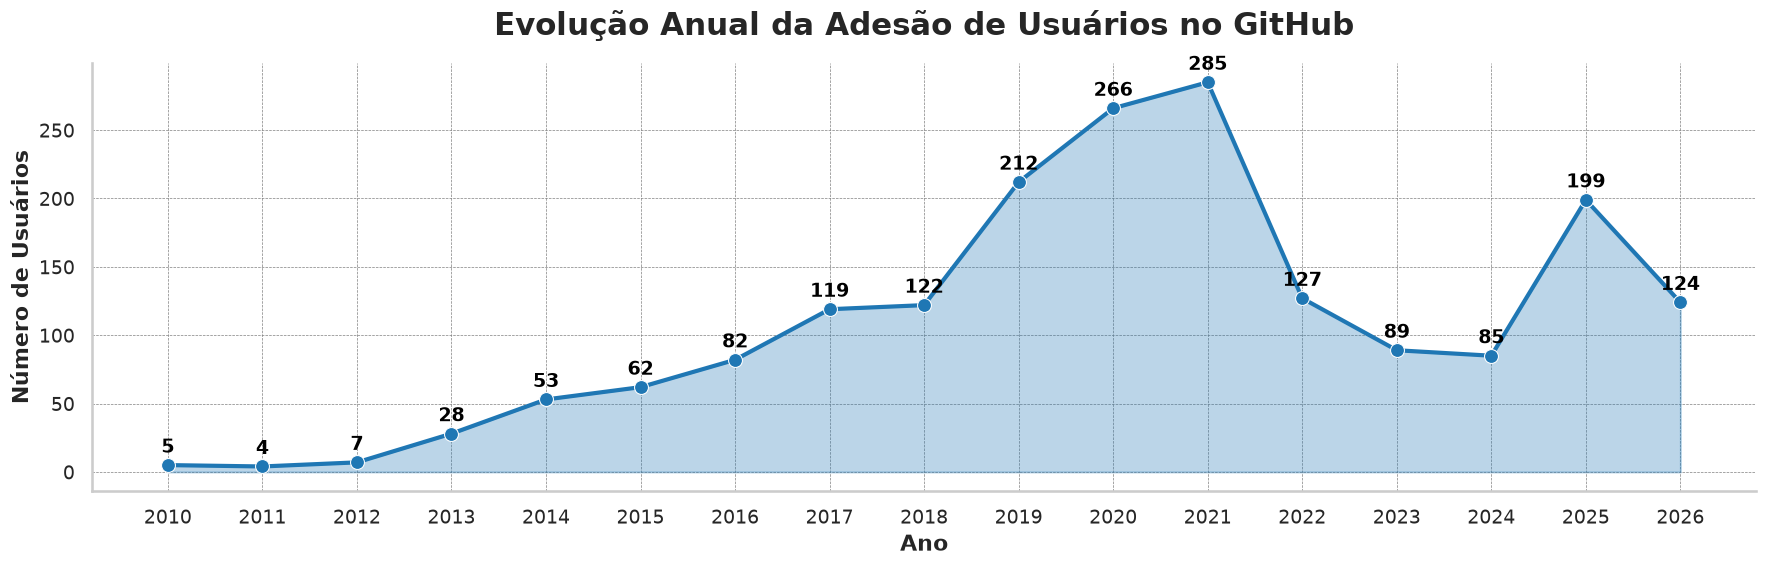

In [10]:
# Converter a coluna 'created_at' para datetime e extrair o ano
users_data['created_at'] = pd.to_datetime(users_data['created_at'])
users_data['year'] = users_data['created_at'].dt.year

# Agrupar por ano e contar os usuários
yearly_counts = users_data.groupby('year').size().reset_index(name='user_count')
yearly_counts = yearly_counts.sort_values('year')

# Configurar o tema e contexto com ajustes adicionais de estilo
sns.set_theme(style="whitegrid", context="talk", rc={
    "axes.titlesize": 22,
    "axes.titleweight": "bold",
    "axes.labelsize": 16,
    "axes.labelweight": "bold",
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "grid.color": "gray",
    "grid.linestyle": "--",
    "grid.linewidth": 0.5,
})

# Criar a figura
plt.figure(figsize=(18, 6))
ax = sns.lineplot(
    x='year',
    y='user_count',
    data=yearly_counts,
    marker='o',
    linewidth=3,
    markersize=10,
    color='#1f77b4'
)

# Adicionar preenchimento abaixo da linha para um efeito de destaque
ax.fill_between(yearly_counts['year'], yearly_counts['user_count'], alpha=0.3, color='#1f77b4')

# Adicionar anotações com os valores de cada ponto
for index, row in yearly_counts.iterrows():
    ax.text(
        row['year'], 
        row['user_count'] + max(yearly_counts['user_count'])*0.02,  # Ajuste para espaçamento dinâmico
        str(row['user_count']),
        ha='center',
        va='bottom',
        fontsize=14,
        fontweight='bold',
        color='black'
    )

# Definir explicitamente todos os anos no eixo x
ax.set_xticks(yearly_counts['year'])

# Remover as bordas superior e direita para um visual mais clean
sns.despine(top=True, right=True)

# Configurar título e rótulos dos eixos
plt.title('Evolução Anual da Adesão de Usuários no GitHub', pad=20)
plt.xlabel('Ano')
plt.ylabel('Número de Usuários')

plt.tight_layout()
plt.show()


## Variação Anual de Criação de Repositórios Públicos

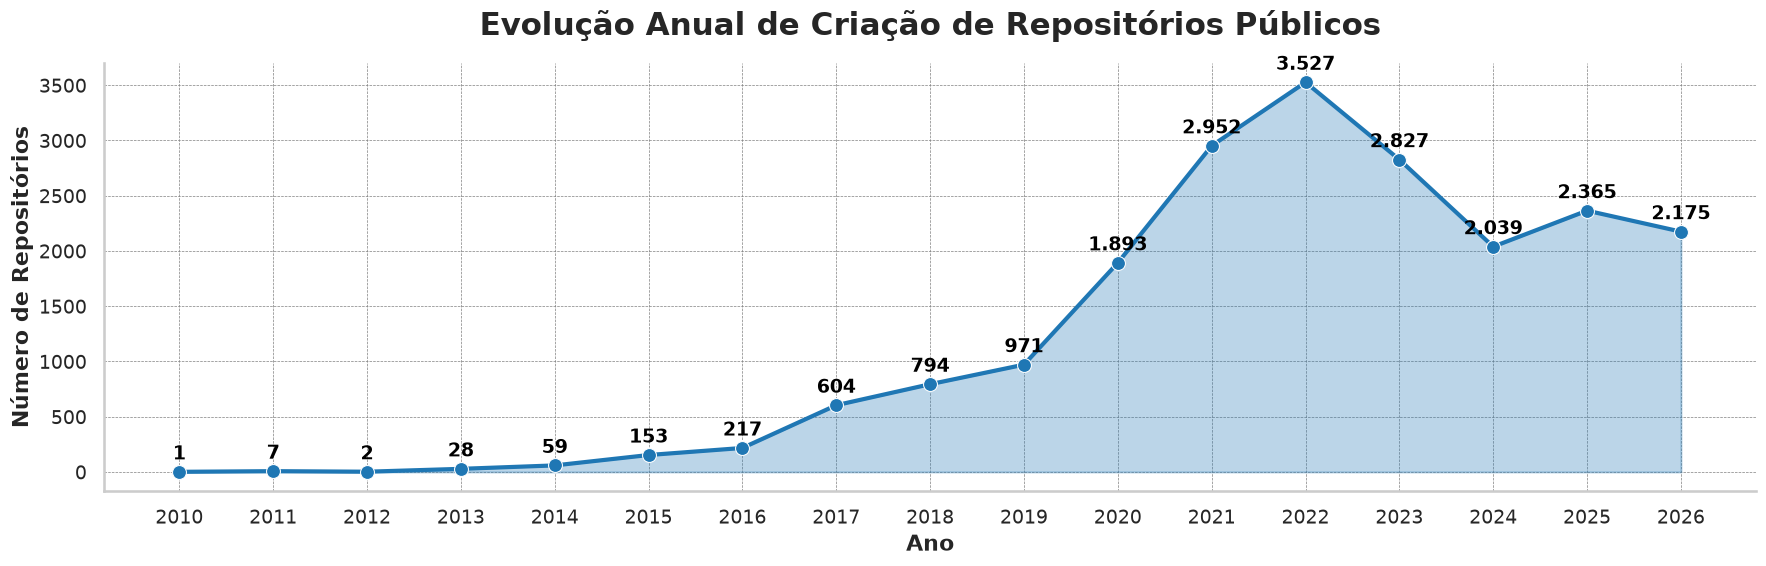

In [11]:
# Converter a coluna 'created_at' para datetime e extrair o ano
repos_data['created_at'] = pd.to_datetime(repos_data['created_at'])
repos_data['year'] = repos_data['created_at'].dt.year

# Agrupar por ano e contar os repositórios
yearly_counts = repos_data.groupby('year').size().reset_index(name='repo_count')
yearly_counts = yearly_counts.sort_values('year')

# Configurar o tema e contexto com ajustes adicionais de estilo
sns.set_theme(style="whitegrid", context="talk", rc={
    "axes.titlesize": 22,
    "axes.titleweight": "bold",
    "axes.labelsize": 16,
    "axes.labelweight": "bold",
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "grid.color": "gray",
    "grid.linestyle": "--",
    "grid.linewidth": 0.5,
})

# Criar a figura e o gráfico de linhas
plt.figure(figsize=(18, 6))
ax = sns.lineplot(
    x='year',
    y='repo_count',
    data=yearly_counts,
    marker='o',
    linewidth=3,
    markersize=10,
    color='#1f77b4'
)

# Preenchimento abaixo da linha para realce visual
ax.fill_between(yearly_counts['year'], yearly_counts['repo_count'], alpha=0.3, color='#1f77b4')

# Adicionar anotações com os valores formatados de cada ponto
for index, row in yearly_counts.iterrows():
    ax.text(
        row['year'], 
        row['repo_count'] + max(yearly_counts['repo_count'])*0.02,  # Espaçamento dinâmico
        f"{row['repo_count']:,}".replace(',', '.'),  # Formata com ponto como separador de milhar
        ha='center',
        va='bottom',
        fontsize=14,
        fontweight='bold',
        color='black'
    )

# Garantir que todos os anos sejam exibidos no eixo x
ax.set_xticks(yearly_counts['year'])

# Remover bordas superior e direita para um visual mais clean
sns.despine(top=True, right=True)

# Configurar título e rótulos dos eixos
plt.title('Evolução Anual de Criação de Repositórios Públicos', pad=20)
plt.xlabel('Ano')
plt.ylabel('Número de Repositórios')

plt.tight_layout()
plt.show()


## Linguagens Mais Usadas em Repositórios Públicos

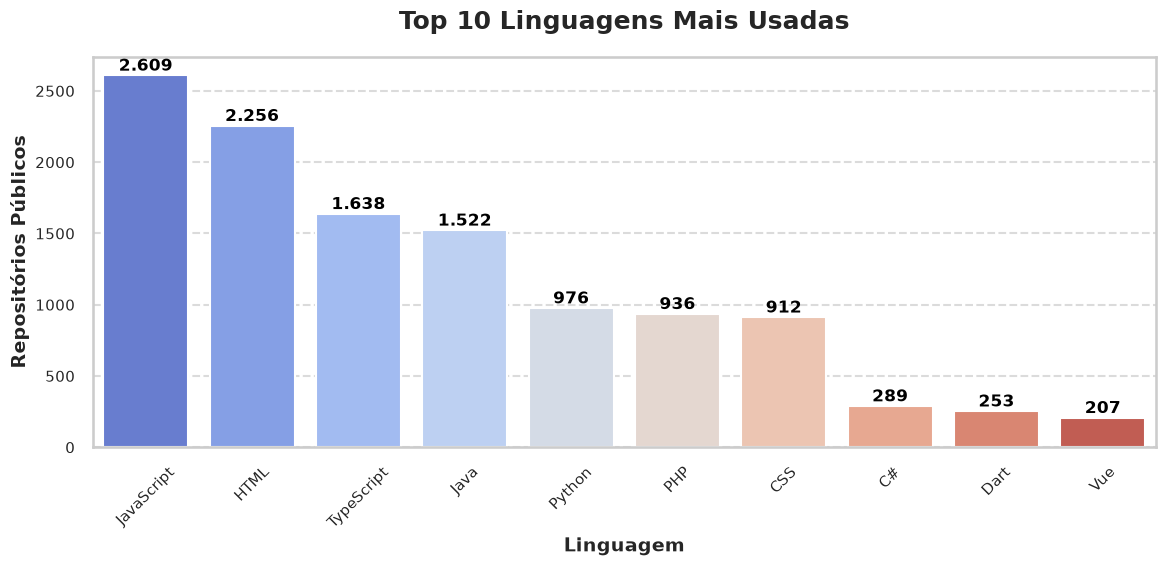

In [12]:
language_counts = repos_data['language'].value_counts().reset_index()
language_counts.columns = ['language', 'count']
top_10_languages = language_counts.head(10)

sns.set_theme(style="whitegrid", context="talk")

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    x='language',
    y='count',
    data=top_10_languages,
    palette='coolwarm'
)

for i, row in top_10_languages.iterrows():
    ax.text(
        i,                           
        row['count'] + 5,            
        f"{row['count']:,}".replace(',', '.'),  
        ha='center',                 
        va='bottom',                 
        fontsize=12,
        fontweight='bold',
        color='black'
    )

plt.title('Top 10 Linguagens Mais Usadas', fontsize=18, fontweight='bold', pad=20)
plt.xlabel('Linguagem', fontsize=14)
plt.ylabel('Repositórios Públicos', fontsize=14)
plt.xticks(rotation=45, fontsize=11)  
plt.yticks(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


## Distribuição de Repositórios Curtidos

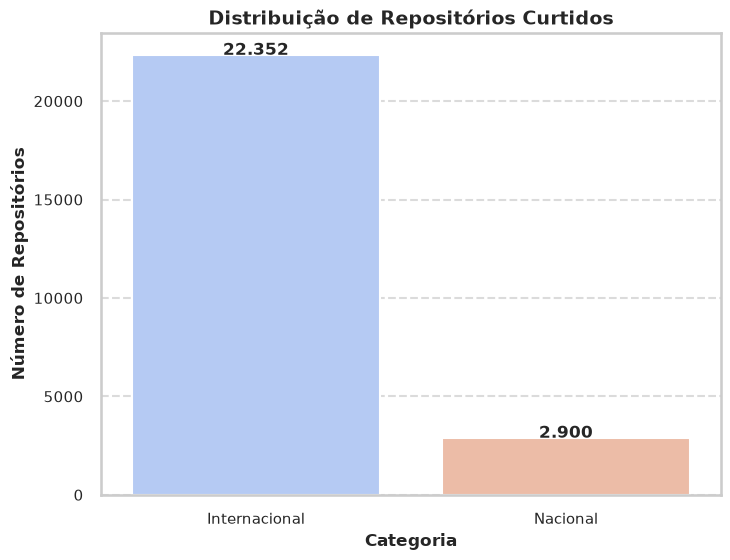

In [13]:
starred_data['nacional'] = starred_data['owner_id'].isin(users_data['id'])
starred_data['categoria'] = starred_data['nacional'].map({True: 'Nacional', False: 'Internacional'})
contagens = starred_data['categoria'].value_counts()

plt.figure(figsize=(8, 6))
sns.barplot(x=contagens.index, y=contagens.values, palette='coolwarm')
plt.title('Distribuição de Repositórios Curtidos', fontsize=14)
plt.xlabel('Categoria', fontsize=12)
plt.ylabel('Número de Repositórios', fontsize=12)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for i, value in enumerate(contagens.values):
    plt.text(i, value + 0.1, f"{value:,.0f}".replace(',', '.'), ha='center', fontsize=12, fontweight='bold')

plt.show()


## Linguagens Mais Curtidas

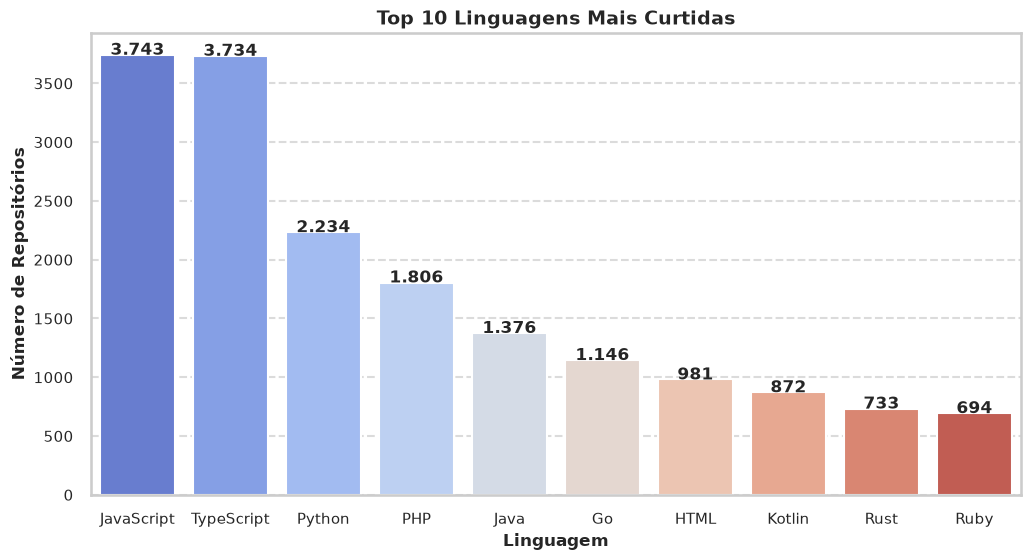

In [14]:
df_languages = starred_data['language'].value_counts().reset_index()
df_languages.columns = ['language', 'count']

df_languages = df_languages.head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=df_languages['language'], y=df_languages['count'], palette='coolwarm')
plt.title('Top 10 Linguagens Mais Curtidas', fontsize=14)
plt.xlabel('Linguagem', fontsize=12)
plt.ylabel('Número de Repositórios', fontsize=12)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for i, value in enumerate(df_languages['count']):
    plt.text(i, value + 0.5, f"{value:,.0f}".replace(',', '.'), ha='center', fontsize=12, fontweight='bold')

plt.show()